# Mini-Project 1 — UBOS District Population Forecaster

**Scenario.** A district planning unit wants 5-year population forecasts (2025–2029) to plan primary-school classrooms.

**Data.** Population estimates in **thousands**, 2015–2024. Kampala, Wakiso and Gulu come from the brief (illustrative). **Mukono** and **Mbarara** were added as required; their figures are also *illustrative* (synthetic), shaped to resemble a fast-growing peri-urban district and a steadier regional-city district.

**Assumptions**
- Population values are mid-year estimates in thousands; years are evenly spaced.
- Model selection uses **RMSE** on the 2022–2024 hold-out (it penalises big misses, which matter most when building classrooms). MAE and MAPE are reported too.
- The selected model is **re-fitted on all 10 years** before forecasting 2025–2029, so the forecast uses the latest information.

All reusable logic lives in `src/population.py` and `src/common/forecasting.py`; this notebook only calls it.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.population import (
    DistrictPopulation, ModelComparison, MODEL_FACTORIES, YEARS,
    classrooms_needed, load_districts, fibonacci_ratios,
)
from src.common.forecasting import bootstrap_prediction_intervals

SEED = 2026                     # fixed seed -> reproducible bootstrap intervals
pd.set_option("display.float_format", "{:,.2f}".format)

## Task 1 — The `DistrictPopulation` class

The class stores years and populations as NumPy arrays, validates them on creation, and implements `__repr__`, `__len__` (and `__getitem__` for lookup by year).

In [2]:
districts = load_districts()
for d in districts:
    print(repr(d), "| len =", len(d))

print("\nKampala in 2020:", districts[0][2020], "thousand")

DistrictPopulation(name='Kampala', years=2015-2024, n=10, latest=1,800k) | len = 10
DistrictPopulation(name='Wakiso', years=2015-2024, n=10, latest=1,670k) | len = 10
DistrictPopulation(name='Gulu', years=2015-2024, n=10, latest=480k) | len = 10
DistrictPopulation(name='Mukono', years=2015-2024, n=10, latest=948k) | len = 10
DistrictPopulation(name='Mbarara', years=2015-2024, n=10, latest=589k) | len = 10

Kampala in 2020: 1500.0 thousand


Validation in action — each bad input is rejected with a clear message:

In [3]:
bad_inputs = {
    "unequal lengths": ([2015, 2016, 2017], [100, 110]),
    "negative value":  ([2015, 2016], [100, -5]),
    "empty":           ([], []),
}
for label, (yrs, pops) in bad_inputs.items():
    try:
        DistrictPopulation("Test", yrs, pops)
    except ValueError as err:
        print(f"{label:16s} -> ValueError: {err}")

unequal lengths  -> ValueError: years (3) and populations (2) differ in length.
negative value   -> ValueError: Populations cannot be negative.
empty            -> ValueError: Years and populations must not be empty.


## Task 2 — Descriptive statistics: `statistics` vs NumPy

In [4]:
rows = []
for d in districts:
    s = d.stats_with_statistics_module()
    n0 = d.stats_with_numpy(ddof=0)
    n1 = d.stats_with_numpy(ddof=1)
    rows.append({
        "District": d.name, "Mean": s["mean"], "Median": s["median"],
        "Var (statistics)": s["variance"], "Var (np, ddof=0)": n0["variance"], "Var (np, ddof=1)": n1["variance"],
        "SD (statistics)": s["std"], "SD (np, ddof=0)": n0["std"],
    })
stats_df = pd.DataFrame(rows).set_index("District")
stats_df

,Mean,Median,Var (statistics),"Var (np, ddof=0)","Var (np, ddof=1)",SD (statistics),"SD (np, ddof=0)"
District,,,,,,,
Kampala,"1,477.00","1,460.00","42,601.11","38,341.00","42,601.11",206.40,195.81
Wakiso,"1,280.00","1,260.00","60,066.67","54,060.00","60,066.67",245.09,232.51
Gulu,389.50,382.50,"2,885.83","2,597.25","2,885.83",53.72,50.96
Mukono,760.00,752.50,"13,554.67","12,199.20","13,554.67",116.42,110.45
Mbarara,529.90,530.00,"1,607.88","1,447.09","1,607.88",40.10,38.04


In [5]:
# Check the relationship by hand for Kampala: var_sample = var_population * n / (n - 1)
k = stats_df.loc["Kampala"]; n = len(districts[0])
print(f"np.var * n/(n-1) = {k['Var (np, ddof=0)'] * n / (n - 1):,.2f}  vs  statistics.variance = {k['Var (statistics)']:,.2f}")

np.var * n/(n-1) = 42,601.11  vs  statistics.variance = 42,601.11


**Why the variances differ.** `statistics.variance` computes the **sample** variance, dividing the sum of squared deviations by $n-1$. `np.var` by default computes the **population** variance, dividing by $n$. With $n = 10$ the NumPy value is exactly $9/10$ of the `statistics` value.

**What `ddof` does.** `ddof` ("delta degrees of freedom") sets the divisor to $n - \text{ddof}$. `ddof=0` → divide by $n$ (treat the data as the whole population); `ddof=1` → divide by $n-1$ (Bessel's correction: an unbiased estimate when the data are a *sample* and the mean was estimated from the same data). `np.var(x, ddof=1)` reproduces `statistics.variance(x)` exactly. The mean and median are identical in both libraries.

## Task 3 — Growth rates and CAGR

In [6]:
growth = pd.DataFrame({d.name: d.yoy_growth() * 100 for d in districts}, index=YEARS[1:])
growth.index.name = "Year"
growth.round(2)

,Kampala,Wakiso,Gulu,Mukono,Mbarara
Year,,,,,
2016,4.17,5.26,3.12,5.33,2.98
2017,4.00,7.00,4.55,4.27,2.48
2018,3.85,7.48,4.35,5.92,3.02
2019,5.19,6.09,4.17,4.44,2.35
2020,5.63,6.56,4.00,6.45,2.68
2021,5.33,6.92,5.13,4.12,2.23
2022,4.43,6.47,4.88,6.06,2.55
2023,4.24,6.08,5.81,4.20,2.49
2024,4.65,6.37,5.49,6.16,2.08


In [7]:
cagr = pd.Series({d.name: d.cagr() * 100 for d in districts}, name="CAGR 2015–2024 (%)").sort_values(ascending=False)
print(cagr.round(2).to_string())
print(f"\nFastest-growing in relative terms: {cagr.index[0]} ({cagr.iloc[0]:.2f}% per year)")

Wakiso    6.47
Mukono    5.21
Kampala   4.61
Gulu      4.61
Mbarara   2.54

Fastest-growing in relative terms: Wakiso (6.47% per year)


**Hand check.** Kampala: $(1800/1200)^{1/9} - 1 = 1.5^{0.111} - 1 \approx 4.61\%$. Gulu grows by the same factor (320 → 480 = ×1.5), so it has the *same* CAGR even though it adds far fewer people. Wakiso ($1670/950 = 1.758$) has the highest CAGR, **≈ 6.47 % a year**, making it the fastest-growing district in relative terms. The year-on-year table shows Wakiso growing 5.3–7.5 % every year, the top rate in almost every year, while Kampala stays between 3.9 % and 5.6 % and Mbarara slows from about 3 % to 2 %.

## Task 4 — Three forecasting models behind one interface

All models subclass the abstract `Forecaster` (in `src/common/forecasting.py`), which exposes `fit(y)` and `predict(horizon)` and does the input checks once:

| Model | Class | Rule |
|---|---|---|
| (a) Linear trend | `LinearTrendForecaster` | least-squares line $y = a + bt$ via `np.polyfit(t, y, 1)` |
| (b) Exponential / CAGR | `CAGRForecaster` | $\hat y_{n+h} = y_n (1+g)^h$ with $g$ = CAGR of the training data |
| (c) Fibonacci ratio | `FibonacciRatioForecaster` | $\hat y_{n+h} = y_n \prod_{k=1}^{h} F_{k+1}/F_k$, ratios 1, 2, 1.5, 1.67, 1.6, … |

Because they share an interface, the evaluation code below can loop over them without knowing which is which (polymorphism).

In [8]:
print("Fibonacci ratios used for a 5-step forecast:", fibonacci_ratios(5).round(3))
demo = districts[0].populations[:7]          # Kampala 2015-2021
for name, factory in MODEL_FACTORIES.items():
    print(f"{name:20s} 2022-2024 forecast:", factory().fit(demo).predict(3).round(0))

Fibonacci ratios used for a 5-step forecast: [1.    2.    1.5   1.667 1.6  ]
Linear trend         2022-2024 forecast: [1623. 1686. 1749.]
Exponential (CAGR)   2022-2024 forecast: [1654. 1732. 1813.]
Fibonacci ratio      2022-2024 forecast: [1580. 3160. 4740.]


## Task 5 — Validate before forecasting (train 2015–2021, test 2022–2024)

In [9]:
comparisons = {d.name: ModelComparison(d, last_train_year=2021, criterion="rmse") for d in districts}
for name, mc in comparisons.items():
    print(f"\n{name}")
    display(pd.DataFrame(mc.table()).drop(columns="District").set_index("Model"))


Kampala


,MAE (k),RMSE (k),MAPE (%),Best
Model,,,,
Linear trend,37.62,38.97,2.17,
Exponential (CAGR),9.62,10.39,0.55,✓
Fibonacci ratio,"1,483.33","1,890.51",83.77,



Wakiso


,MAE (k),RMSE (k),MAPE (%),Best
Model,,,,
Linear trend,49.40,52.37,3.09,
Exponential (CAGR),6.80,8.05,0.42,✓
Fibonacci ratio,"1,266.67","1,604.39",77.62,



Gulu


,MAE (k),RMSE (k),MAPE (%),Best
Model,,,,
Linear trend,18.57,20.29,4.01,
Exponential (CAGR),9.44,10.87,2.02,✓
Fibonacci ratio,378.33,481.71,80.37,



Mukono


,MAE (k),RMSE (k),MAPE (%),Best
Model,,,,
Linear trend,23.69,25.57,2.60,
Exponential (CAGR),6.33,7.53,0.70,✓
Fibonacci ratio,749.33,949.33,80.79,



Mbarara


,MAE (k),RMSE (k),MAPE (%),Best
Model,,,,
Linear trend,0.45,0.57,0.08,✓
Exponential (CAGR),1.98,2.61,0.34,
Fibonacci ratio,531.00,680.93,90.80,


In [10]:
best = pd.DataFrame(
    [{"District": n, "Selected model": mc.best.model, "Test RMSE (k)": mc.best.rmse, "Test MAPE (%)": mc.best.mape}
     for n, mc in comparisons.items()]
).set_index("District")
best

,Selected model,Test RMSE (k),Test MAPE (%)
District,,,
Kampala,Exponential (CAGR),10.39,0.55
Wakiso,Exponential (CAGR),8.05,0.42
Gulu,Exponential (CAGR),10.87,2.02
Mukono,Exponential (CAGR),7.53,0.70
Mbarara,Linear trend,0.57,0.08


The exponential (CAGR) model wins for the four districts whose growth is compounding (Kampala, Wakiso, Gulu, Mukono): a straight line fitted to 2015–2021 under-predicts 2022–2024 because the yearly increments keep getting bigger. For Mbarara, whose yearly increments are roughly constant (~13k), the linear trend wins. The Fibonacci-ratio model is wrong by 78–91 % on every district. Doubling the population in year 2 is not a forecast.

**Second-method check:** for Kampala, CAGR on 2015–2021 is $(1580/1200)^{1/6}-1 = 4.69\%$, so the 2022 forecast is $1580 \times 1.0469 \approx 1654$ vs the actual 1650: consistent with the small test error in the table.

## Task 6 — Forecast 2025–2029 with the selected model (plus bootstrap intervals — extension)

In [11]:
H = 5
FUTURE_YEARS = np.arange(2025, 2025 + H)
forecasts = {}
for d in districts:
    factory = MODEL_FACTORIES[comparisons[d.name].best.model]
    point, lo, hi = bootstrap_prediction_intervals(factory, d.populations, H, n_boot=2000, level=0.95, seed=SEED)
    forecasts[d.name] = {"model": factory.name, "point": point, "lo": lo, "hi": hi}

fc_table = pd.DataFrame({n: f["point"] for n, f in forecasts.items()}, index=FUTURE_YEARS).T
fc_table.columns.name = "Forecast (thousands)"
fc_table.round(0)

Forecast (thousands),2025,2026,2027,2028,2029
Kampala,"1,883.00","1,970.00","2,060.00","2,155.00","2,255.00"
Wakiso,"1,778.00","1,893.00","2,015.00","2,146.00","2,285.00"
Gulu,502.00,525.00,549.00,575.00,601.00
Mukono,997.00,"1,049.00","1,104.00","1,162.00","1,222.00"
Mbarara,603.00,616.00,629.00,642.00,656.00


In [12]:
var_rows = []
for d in districts:
    f = forecasts[d.name]["point"]
    fitted = MODEL_FACTORIES[forecasts[d.name]["model"]]().fit(d.populations)
    var_rows.append({
        "District": d.name,
        "Var actual 2015–24": np.var(d.populations, ddof=1),
        "Var forecast 2025–29": np.var(f, ddof=1),
        "Var of actual residuals": np.var(fitted.residuals(), ddof=1),
        "Var of forecast residuals": 0.0,
        "Avg yearly change actual": np.diff(d.populations).mean(),
        "Avg yearly change forecast": np.diff(np.r_[d.populations[-1], f]).mean(),
    })
pd.DataFrame(var_rows).set_index("District").round(1)

,Var actual 2015–24,Var forecast 2025–29,Var of actual residuals,Var of forecast residuals,Avg yearly change actual,Avg yearly change forecast
District,,,,,,
Kampala,"42,601.10","21,607.70",98.80,0.00,66.70,91.00
Wakiso,"60,066.70","40,131.40",30.90,0.00,80.00,122.90
Gulu,"2,885.80","1,536.50",13.80,0.00,17.80,24.30
Mukono,"13,554.70","7,903.40",13.60,0.00,38.70,54.90
Mbarara,"1,607.90",438.40,0.40,0.00,13.20,13.30


**What the variance comparison tells us.** For a trending series, the variance mostly measures **how far the trend travels during the window**, not randomness. The actual series covers 10 years and the forecast covers only 5, so the forecast variance is smaller even though the forecast grows *faster* per year (the average yearly change is higher in every district). This shows that raw variance of a trended series is not a measure of volatility. The more useful comparison is the last two columns of the residual variance: the actual data wobble around their trend, while the point forecast is a perfectly smooth curve with **zero** wobble. The point forecast therefore understates real-world uncertainty, which is why the prediction intervals below are needed.

## Task 7 — Actual, fitted and forecast values on one figure

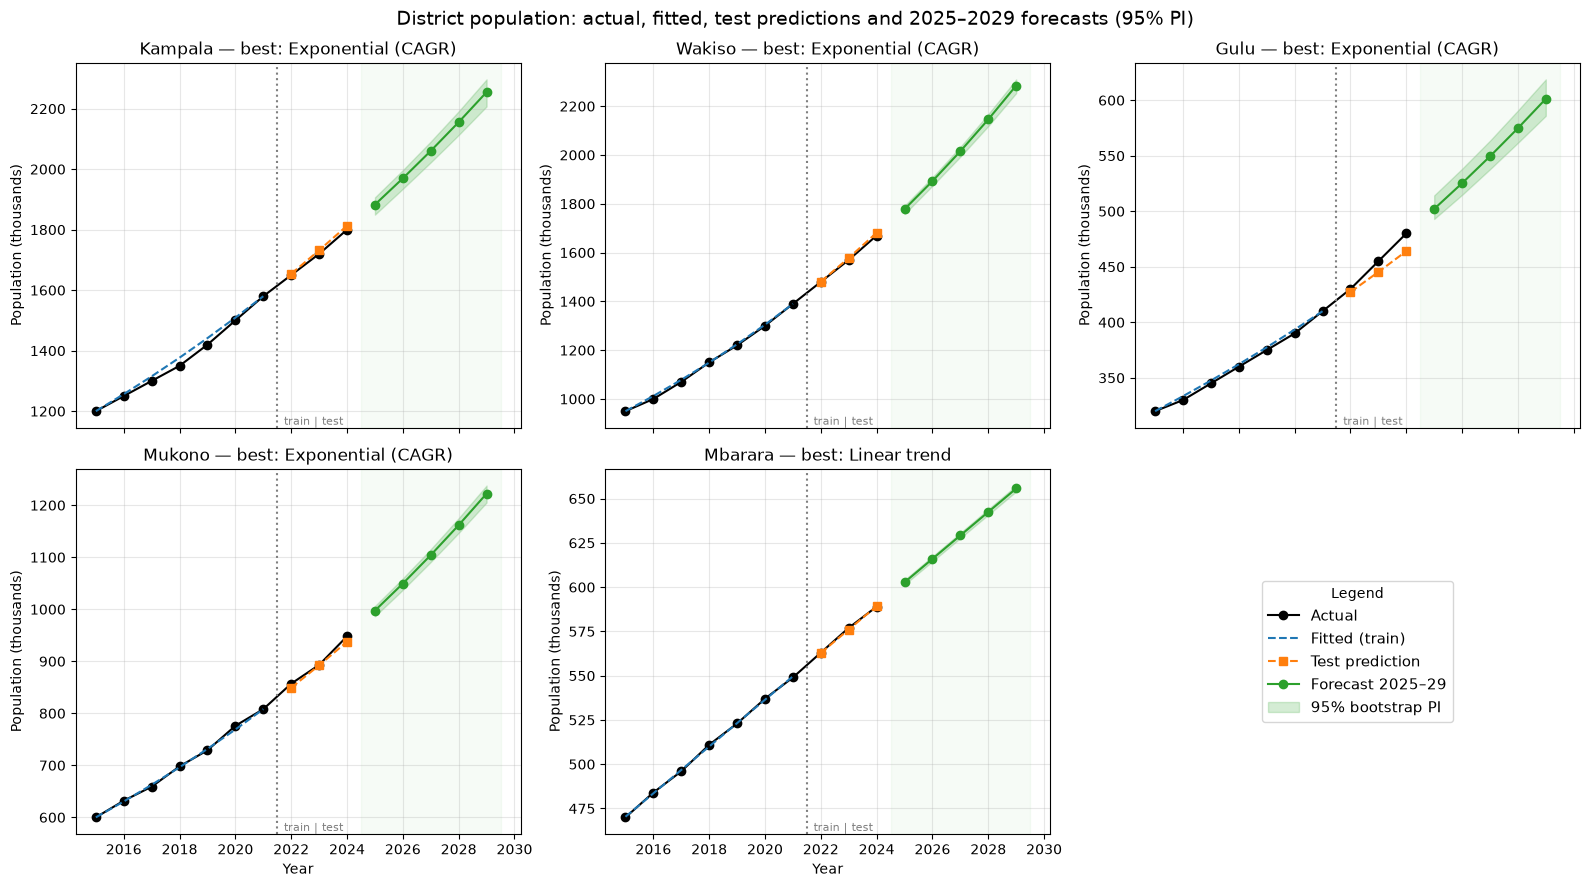

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharex=True)
axes = axes.ravel()
for ax, d in zip(axes, districts):
    mc = comparisons[d.name]
    model_name = mc.best.model
    train_model = MODEL_FACTORIES[model_name]().fit(mc.train.populations)
    ax.plot(d.years, d.populations, "o-", color="black", lw=1.5, label="Actual")
    ax.plot(mc.train.years, train_model.fitted_values(), "--", color="tab:blue", label="Fitted (train)")
    ax.plot(mc.test.years, mc.best.predictions, "s--", color="tab:orange", label="Test prediction")
    f = forecasts[d.name]
    ax.plot(FUTURE_YEARS, f["point"], "o-", color="tab:green", label="Forecast 2025–29")
    ax.fill_between(FUTURE_YEARS, f["lo"], f["hi"], color="tab:green", alpha=0.2, label="95% bootstrap PI")
    ax.axvline(2021.5, color="grey", ls=":", lw=1.5)
    ax.text(2021.6, ax.get_ylim()[0], " train | test", color="grey", va="bottom", fontsize=8)
    ax.axvspan(2024.5, 2029.5, color="tab:green", alpha=0.04)
    ax.set_title(f"{d.name} — best: {model_name}")
    ax.set_ylabel("Population (thousands)")
    ax.grid(alpha=0.3)
for ax in axes[3:]:
    ax.set_xlabel("Year")
axes[-1].axis("off")
handles, labels = axes[0].get_legend_handles_labels()
axes[-1].legend(handles, labels, loc="center", fontsize=11, title="Legend")
fig.suptitle("District population: actual, fitted, test predictions and 2025–2029 forecasts (95% PI)", fontsize=14)
fig.tight_layout()
fig.savefig("figures/p1_population_forecasts.png", dpi=150)
plt.show()

## Task 8 — Planning output: additional classrooms by 2029

Additional classrooms $= \left\lceil \dfrac{0.18 \times (P_{2029} - P_{2024}) \times 1000}{53} \right\rceil$ (populations are in thousands). The range uses the lower and upper ends of the 95 % prediction interval, so planners can see the best and worst cases.

In [14]:
plan = []
for d in districts:
    f = forecasts[d.name]
    now = d.populations[-1]
    plan.append({
        "District": d.name,
        "Pop 2024 (k)": now,
        "Forecast 2029 (k)": f["point"][-1],
        "Extra school-age children": 0.18 * (f["point"][-1] - now) * 1000,
        "Classrooms (central)": classrooms_needed(now, f["point"][-1]),
        "Classrooms (low, PI)": classrooms_needed(now, f["lo"][-1]),
        "Classrooms (high, PI)": classrooms_needed(now, f["hi"][-1]),
    })
plan_df = pd.DataFrame(plan).set_index("District")
plan_df["Extra school-age children"] = plan_df["Extra school-age children"].round(0)
plan_df.round(1)

,Pop 2024 (k),Forecast 2029 (k),Extra school-age children,Classrooms (central),"Classrooms (low, PI)","Classrooms (high, PI)"
District,,,,,,
Kampala,"1,800.00","2,254.80","81,857.00",1545,1384,1688
Wakiso,"1,670.00","2,284.70","110,641.00",2088,1983,2174
Gulu,480.00,601.30,"21,829.00",412,360,472
Mukono,948.00,"1,222.30","49,372.00",932,874,985
Mbarara,589.00,655.70,"12,007.00",227,221,233


In [15]:
# Hand check for Kampala
k_2029 = forecasts["Kampala"]["point"][-1]
print(f"0.18 * ({k_2029:.1f} - 1800) * 1000 / 53 = {0.18 * (k_2029 - 1800) * 1000 / 53:.1f} -> round up")

0.18 * (2254.8 - 1800) * 1000 / 53 = 1544.5 -> round up


## Extension — Is the Fibonacci-ratio model defensible?

The model multiplies the last value by $1, 2, 1.5, 1.67, 1.6, 1.625, \dots$, which converges to the golden ratio $\varphi \approx 1.618$. So it assumes:

1. **A fixed growth path that ignores the data.** `fit()` learns nothing. Kampala, Gulu and Mbarara all get the same percentage path, which contradicts their different CAGRs (2.6–6.5 %).
2. **Roughly 62 % growth per period in the long run** (and 100 % in the second step). For annual human populations that is impossible: the fastest-growing districts in the region grow at about 3–7 % a year.
3. **Fibonacci dynamics.** The Fibonacci recurrence $F_{n+1}=F_n+F_{n-1}$ describes idealised breeding with no deaths or migration (Fibonacci's rabbits). It is defensible only if each period's increase equals the previous period's total population. That could hold for a newly colonising species with unlimited resources and a time step of about one generation, not for a district measured in calendar years.

It could be *made* defensible only by (a) redefining one "step" as roughly the time the population takes to grow by 62 % (about 10 years at 5 %), which throws away the annual detail, or (b) using the ratios as a shape and rescaling them to the observed growth rate, at which point it is just the CAGR model. The test errors (MAPE 78–91 %) confirm it should not be used for planning.

## Findings & Limitations

**Findings.** Four of the five districts are growing *multiplicatively*: each year adds more people than the year before, so an exponential (CAGR) model beat a straight line on the 2022–2024 hold-out, with test errors under 1 % for Kampala, Wakiso and Mukono. Mbarara adds a roughly constant ~13k people a year, so the linear trend fitted it best. Choosing the model per district mattered, because a single model for all five would have been wrong somewhere. Wakiso is the planning priority: it has the highest relative growth (6.5 % a year) and the largest absolute increase, so it needs about **2,090 extra classrooms by 2029**, more than Kampala (~1,550) despite starting smaller. Across the five districts that is roughly 5,200 classrooms in five years, over 1,000 a year. The bootstrap intervals give a planning range (e.g. Kampala 1,384–1,688), which is more honest than a single number. The Fibonacci-ratio model failed on every district (MAPE 78–91 %) because it ignores the data entirely.

**Limitations.** (1) The data are illustrative and only 10 points long. With 7 training years the hold-out has just 3 points, so "best model" is decided on very little evidence. (2) Exponential growth cannot continue indefinitely; fertility decline, migration policy or land constraints (particularly in Kampala) would bend the curve, and none of our models can anticipate that. (3) The 18 % school-age share and 53 pupils per classroom are held constant, and the estimate ignores existing spare capacity, private schools and enrolment rates. (4) The bootstrap intervals only reflect the noise seen in 2015–2024. They do not cover structural shocks (a census revision, a new district boundary), so the true uncertainty is wider than shown.